# Fase 4 — Modelagem (CRISP-DM)

**Pergunta:** quais fatores (experiência/ambiente, tipo de cozinha, faixa de preço e localidade) mais influenciam a avaliação média e a recomendação de estabelecimentos gastronômicos?
Documento: [`fase4-modelagem.md`](../fase4-modelagem.md) · Base: `dados/processados/` (gerada pelo notebook da Fase 3) · Semente: 42

> Base de demonstração **fictícia**. Os testes medem padrões **desta base**, não de consumidores reais.

In [1]:
import sys, platform, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# No Colab: clone o repositório e entre na pasta do projeto antes de rodar
#   !git clone https://github.com/gabriellandimdonadel/aprendizado-maquina-udf.git
#   %cd aprendizado-maquina-udf/Projeto_datascience/notebooks
RAIZ = Path("..").resolve()
sys.path.insert(0, str(RAIZ / "src"))
BRUTOS, PROCESSADOS, FIGURAS = RAIZ / "dados" / "brutos", RAIZ / "dados" / "processados", RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)
SEMENTE = 42
np.random.seed(SEMENTE)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False})
FONTE = "Fonte: GastroMatch, base de demonstração gastromatch-demo (dados fictícios), exportada em 25/11/2026"
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | semente {SEMENTE}")

import seaborn as sns
from scipy.stats import kruskal, spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from recomendacao import recomendar, PESOS, PONTUACAO_MINIMA

rest = pd.read_csv(PROCESSADOS / "gastromatch_restaurantes.csv")
longa = pd.read_csv(PROCESSADOS / "gastromatch_vibes_longa.csv")
aval = pd.DataFrame(json.load(open(BRUTOS / "firestore_avaliacoes.json", encoding="utf-8")))
print(f"{len(rest)} restaurantes | {len(longa)} pares restaurante×experiência | {len(aval)} avaliações")

Python 3.11.9 | pandas 3.1.1 | numpy 2.4.6 | semente 42


188 restaurantes | 429 pares restaurante×experiência | 1751 avaliações


## 4.1 Concentração da oferta (Pareto) e pesos do motor de recomendação

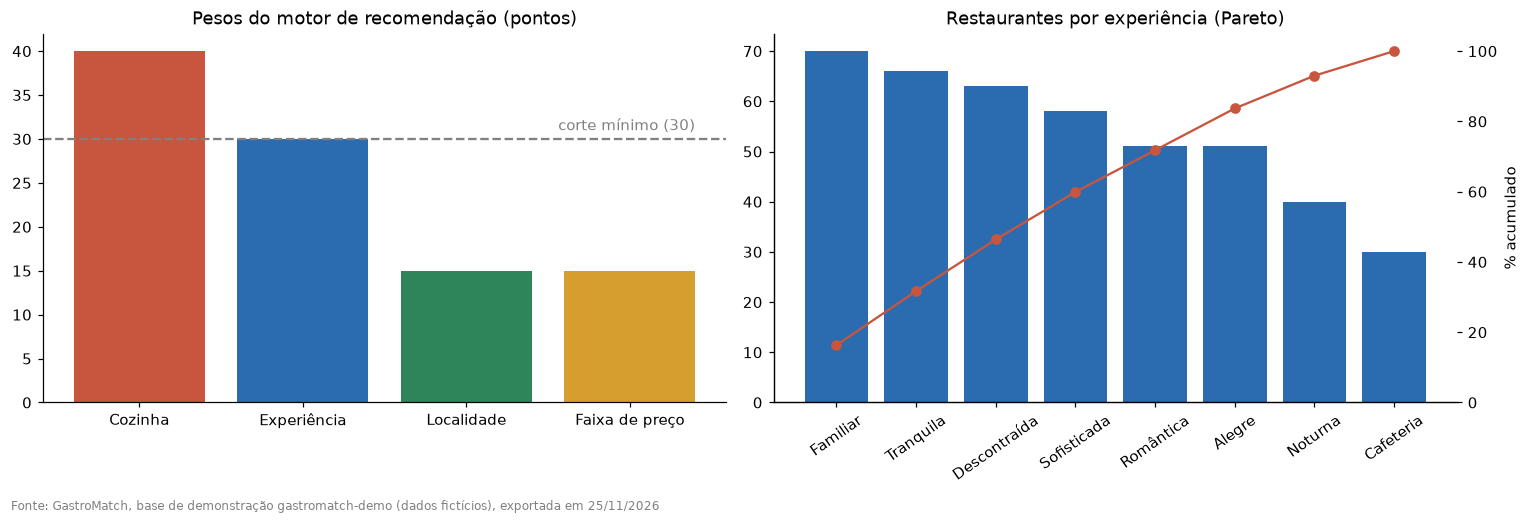

vibe
Familiar        16.3
Tranquila       15.4
Descontraída    14.7
Sofisticada     13.5
Romântica       11.9
Alegre          11.9
Noturna          9.3
Cafeteria        7.0


In [2]:
vc = longa["vibe"].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ax[0].bar(["Cozinha", "Experiência", "Localidade", "Faixa de preço"], list(PESOS.values()), color=["#c8553d", "#2b6cb0", "#2f855a", "#d69e2e"])
ax[0].axhline(PONTUACAO_MINIMA, ls="--", c="gray"); ax[0].text(3.4, PONTUACAO_MINIMA + 1, "corte mínimo (30)", ha="right", color="gray")
ax[0].set_title("Pesos do motor de recomendação (pontos)")
ax[1].bar(vc.index, vc.values, color="#2b6cb0"); ax2 = ax[1].twinx()
ax2.plot(vc.index, 100 * vc.cumsum() / vc.sum(), "o-", c="#c8553d"); ax2.set_ylim(0, 105); ax2.set_ylabel("% acumulado")
ax[1].set_title("Restaurantes por experiência (Pareto)"); ax[1].tick_params(axis="x", rotation=35)
fig.text(0.01, -0.02, FONTE, fontsize=8, color="gray"); plt.tight_layout()
plt.savefig(FIGURAS / "fig1_distribuicao_vibes.png", bbox_inches="tight"); plt.show()
print((100 * vc / vc.sum()).round(1).to_string())

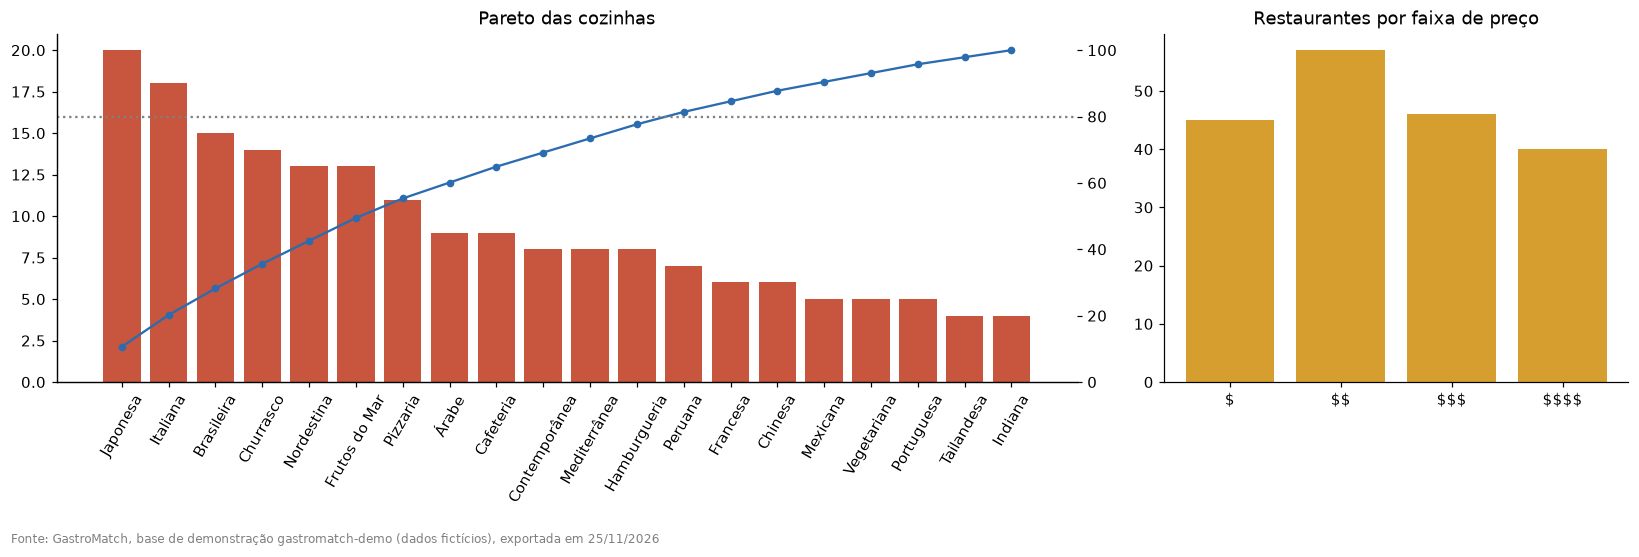

Top 5 cozinhas = 42.6% da oferta; 13 de 20 cozinhas somam 80%
Faixas: {'$': 45, '$$': 57, '$$$': 46, '$$$$': 40}


In [3]:
cz = rest["cozinha"].value_counts()
acum = 100 * cz.cumsum() / cz.sum()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].bar(cz.index, cz.values, color="#c8553d"); a2 = ax[0].twinx(); a2.plot(cz.index, acum, "o-", c="#2b6cb0", ms=4)
a2.axhline(80, ls=":", c="gray"); a2.set_ylim(0, 105); ax[0].tick_params(axis="x", rotation=60); ax[0].set_title("Pareto das cozinhas")
tab = pd.crosstab(rest["faixa_preco"].map({1: "$", 2: "$$", 3: "$$$", 4: "$$$$"}), "restaurantes").iloc[:, 0].reindex(["$", "$$", "$$$", "$$$$"])
ax[1].bar(tab.index, tab.values, color="#d69e2e"); ax[1].set_title("Restaurantes por faixa de preço")
fig.text(0.01, -0.04, FONTE, fontsize=8, color="gray"); plt.tight_layout()
plt.savefig(FIGURAS / "fig2_pareto_cozinhas.png", bbox_inches="tight"); plt.show()
print(f"Top 5 cozinhas = {100 * cz.head(5).sum() / cz.sum():.1f}% da oferta; {int((acum < 80).sum()) + 1} de {len(cz)} cozinhas somam 80%")
print("Faixas:", tab.to_dict())

## 4.2 A nota varia com experiência, faixa, cozinha ou estado? (Kruskal-Wallis)

O teste é feito em dois níveis:
- **Avaliação** (n = 1.213): é o nível mais usado, mas avaliações do mesmo restaurante não são independentes, o que infla a significância (pseudorreplicação).
- **Restaurante** (n = 177 com nota): é a unidade correta, porque cada restaurante entra uma vez.

In [4]:
ar = aval[aval["alvo"] == "restaurante"].merge(rest[["restaurante_id", "faixa_preco", "cozinha", "estado", "vibes_lista"]],
                                                left_on="restauranteId", right_on="restaurante_id")
ar_v = ar.assign(vibe=ar["vibes_lista"].str.split("; ")).explode("vibe")
rn = rest.dropna(subset=["nota_media"]); rn_v = longa.dropna(subset=["nota_media"])

def kw(df, grupo, y):
    gs = [g[y].values for _, g in df.groupby(grupo) if len(g) >= 2]
    h, p = kruskal(*gs)
    return round(h, 2), p, len(gs), len(df)

linhas = []
for nome, g, (d_av, d_r) in [("experiência (vibe)", "vibe", (ar_v, rn_v)), ("faixa de preço", "faixa_preco", (ar, rn)),
                              ("cozinha", "cozinha", (ar, rn)), ("estado", "estado", (ar, rn))]:
    h1, p1, k1, n1 = kw(d_av, g, "nota"); h2, p2, k2, n2 = kw(d_r, g, "nota_media")
    linhas.append({"fator": nome, "grupos": k2, "H (avaliação)": h1, "p (avaliação)": p1, "H (restaurante)": h2, "p (restaurante)": p2,
                   "conclusão (restaurante, α = 0,05)": "diferença significativa" if p2 < .05 else "sem diferença significativa"})
testes = pd.DataFrame(linhas)
testes.style.format({"p (avaliação)": "{:.2g}", "p (restaurante)": "{:.3f}"})

,fator,grupos,H (avaliação),p (avaliação),H (restaurante),p (restaurante),"conclusão (restaurante, α = 0,05)"
0,experiência (vibe),8,6.120000,0.53,2.910000,0.893,sem diferença significativa
1,faixa de preço,4,0.820000,0.84,0.660000,0.884,sem diferença significativa
2,cozinha,20,69.820000,9.8e-08,21.660000,0.301,sem diferença significativa
3,estado,12,43.340000,9.5e-06,17.660000,0.090,sem diferença significativa


In [5]:
print("Nota média por experiência (nível restaurante):")
print(rn_v.groupby("vibe")["nota_media"].agg(["mean", "median", "count"]).round(2).sort_values("mean").to_string())

Nota média por experiência (nível restaurante):
              mean  median  count
vibe                             
Cafeteria     3.91    3.84     28
Descontraída  3.94    3.95     62
Tranquila     3.94    4.00     59
Familiar      3.96    4.00     68
Alegre        4.00    4.00     48
Romântica     4.02    4.00     50
Noturna       4.03    4.00     36
Sofisticada   4.05    4.00     55


## 4.3 Correlações de Spearman

In [6]:
cols = {"faixa_preco": "faixa de preço", "qtd_vibes": "nº de vibes", "total_avaliacoes": "nº de avaliações",
        "nota_media": "nota média", "preco_medio_cardapio": "preço médio", "preco_mediano_principal": "preço prato principal"}
rho = rest[list(cols)].rename(columns=cols).corr(method="spearman")
sig = []
for i, a in enumerate(cols):
    for b in list(cols)[i + 1:]:
        x = rest[[a, b]].dropna(); s = spearmanr(x[a], x[b])
        sig.append({"par": f"{cols[a]} × {cols[b]}", "rho": round(s.statistic, 3), "p": s.pvalue, "n": len(x)})
sig = pd.DataFrame(sig).sort_values("p")
vibes_cols = [c for c in rest.columns if c.startswith("vibe_")]
fv = pd.DataFrame([{"experiência": c.replace("vibe_", ""), "rho com faixa": round(spearmanr(rest["faixa_preco"], rest[c]).statistic, 3),
                    "p": spearmanr(rest["faixa_preco"], rest[c]).pvalue,
                    **{f"% na faixa {k}": round(100 * v, 0) for k, v in rest.groupby("faixa_preco")[c].mean().items()}} for c in vibes_cols])
sig.style.format({"p": "{:.2g}"})

,par,rho,p,n
14,preço médio × preço prato principal,0.956000,3.4e-100,186
4,faixa de preço × preço prato principal,0.715000,2e-30,186
3,faixa de preço × preço médio,0.707000,8.2e-30,188
1,faixa de preço × nº de avaliações,-0.204000,0.0051,188
10,nº de avaliações × preço médio,-0.156000,0.033,188
13,nota média × preço prato principal,0.135000,0.074,175
11,nº de avaliações × preço prato principal,-0.112000,0.13,186
12,nota média × preço médio,0.082000,0.28,177
5,nº de vibes × nº de avaliações,0.070000,0.34,188
9,nº de avaliações × nota média,-0.048000,0.53,177


In [7]:
fv.sort_values("rho com faixa").style.format({"p": "{:.3f}"})

,experiência,rho com faixa,p,% na faixa 1,% na faixa 2,% na faixa 3,% na faixa 4
5,descontraida,-0.225000,0.002,47.000000,42.000000,20.000000,22.000000
1,alegre,-0.062000,0.397,36.000000,26.000000,15.000000,32.000000
4,familiar,-0.051000,0.489,33.000000,47.000000,35.000000,30.000000
2,tranquila,-0.036000,0.627,36.000000,39.000000,33.000000,32.000000
6,noturna,-0.002000,0.980,22.000000,19.000000,24.000000,20.000000
7,cafeteria,0.012000,0.873,20.000000,11.000000,15.000000,20.000000
0,romantica,0.184000,0.012,20.000000,14.000000,46.000000,32.000000
3,sofisticada,0.252000,0.000,11.000000,28.000000,46.000000,40.000000


## 4.4 Simulação do motor de recomendação (500 buscas)

`src/recomendacao.py` é a tradução da regra de `app/src/lib/recomendacao.js`. Nas mesmas 500 buscas, a versão Python e a JavaScript devolveram resultados idênticos (restaurantes, pontos, ordem e situação: **500/500**).

Gerador de buscas, com semente 42:
- 1 ou 2 experiências.
- Cozinha em 70% das buscas.
- Cidade em 80% e bairro em 40% das buscas com cidade.
- Faixa de preço em 60%.

Cada busca devolve até 5 restaurantes com pontuação ≥ 30.

In [8]:
R = [{"id": d["id"], "cozinha": d["cozinha"], "experiencias": d.get("vibes") or [], "cidade": d["cidade"], "bairro": d["bairro"],
      "faixaPreco": d["faixaPreco"], "notaMedia": d.get("notaMedia") or 0, "totalAvaliacoes": d.get("totalAvaliacoes") or 0}
     for d in json.load(open(BRUTOS / "firestore_restaurantes.json", encoding="utf-8"))]
rng = np.random.default_rng(SEMENTE)
VIBES = ["Romântica", "Alegre", "Tranquila", "Sofisticada", "Familiar", "Descontraída", "Noturna", "Cafeteria"]
COZ, CID = sorted({r["cozinha"] for r in R}), sorted({r["cidade"] for r in R})
buscas = []
for _ in range(500):
    cid = str(rng.choice(CID)) if rng.random() < .8 else ""
    bairros = sorted({r["bairro"] for r in R if r["cidade"] == cid})
    buscas.append({"experiencias": [str(v) for v in rng.choice(VIBES, int(rng.integers(1, 3)), replace=False)],
                   "cozinha": str(rng.choice(COZ)) if rng.random() < .7 else "", "cidade": cid,
                   "bairro": str(rng.choice(bairros)) if cid and rng.random() < .4 else "",
                   "preco": int(rng.integers(1, 5)) if rng.random() < .6 else 0})

aparicoes = {r["id"]: 0 for r in R}; pontos_por_rest = {r["id"]: [] for r in R}; situacoes = []; pontos = []
for b in buscas:
    itens, sit = recomendar(R, b); situacoes.append(sit)
    for r_, p in itens:
        aparicoes[r_["id"]] += 1; pontos_por_rest[r_["id"]].append(p); pontos.append(p)
rest["aparicoes_simulacao"] = rest["restaurante_id"].map(aparicoes)
rest["score_medio_simulado"] = rest["restaurante_id"].map(lambda i: np.mean(pontos_por_rest[i]) if pontos_por_rest[i] else np.nan).round(1)
print("Situações:", pd.Series(situacoes).value_counts().to_dict())
print(f"Pontuação dos itens recomendados: média {np.mean(pontos):.1f}, mínimo {min(pontos)}, máximo {max(pontos)}")
por_qtd = rest.groupby("qtd_vibes")["aparicoes_simulacao"].agg(["mean", "count"]).round(2)
print("\nAparições médias por nº de experiências declaradas:"); print(por_qtd.to_string())
print(f"Razão 3 vibes ÷ 1 vibe: {por_qtd.loc[3, 'mean'] / por_qtd.loc[1, 'mean']:.2f}×")
for c, nome in [("qtd_vibes", "nº de vibes"), ("nota_media", "nota média"), ("faixa_preco", "faixa de preço")]:
    x = rest[["aparicoes_simulacao", c]].dropna(); s = spearmanr(x["aparicoes_simulacao"], x[c])
    print(f"Spearman aparições × {nome}: rho = {s.statistic:.3f} (p = {s.pvalue:.2g})")

Situações: {'normal': 264, 'cozinha-em-outra-cidade': 236}
Pontuação dos itens recomendados: média 74.4, mínimo 33, máximo 100

Aparições médias por nº de experiências declaradas:
            mean  count
qtd_vibes              
1           8.03     34
2          11.18     67
3          12.36     87
Razão 3 vibes ÷ 1 vibe: 1.54×
Spearman aparições × nº de vibes: rho = 0.214 (p = 0.0032)
Spearman aparições × nota média: rho = 0.500 (p = 1.3e-12)
Spearman aparições × faixa de preço: rho = -0.045 (p = 0.54)


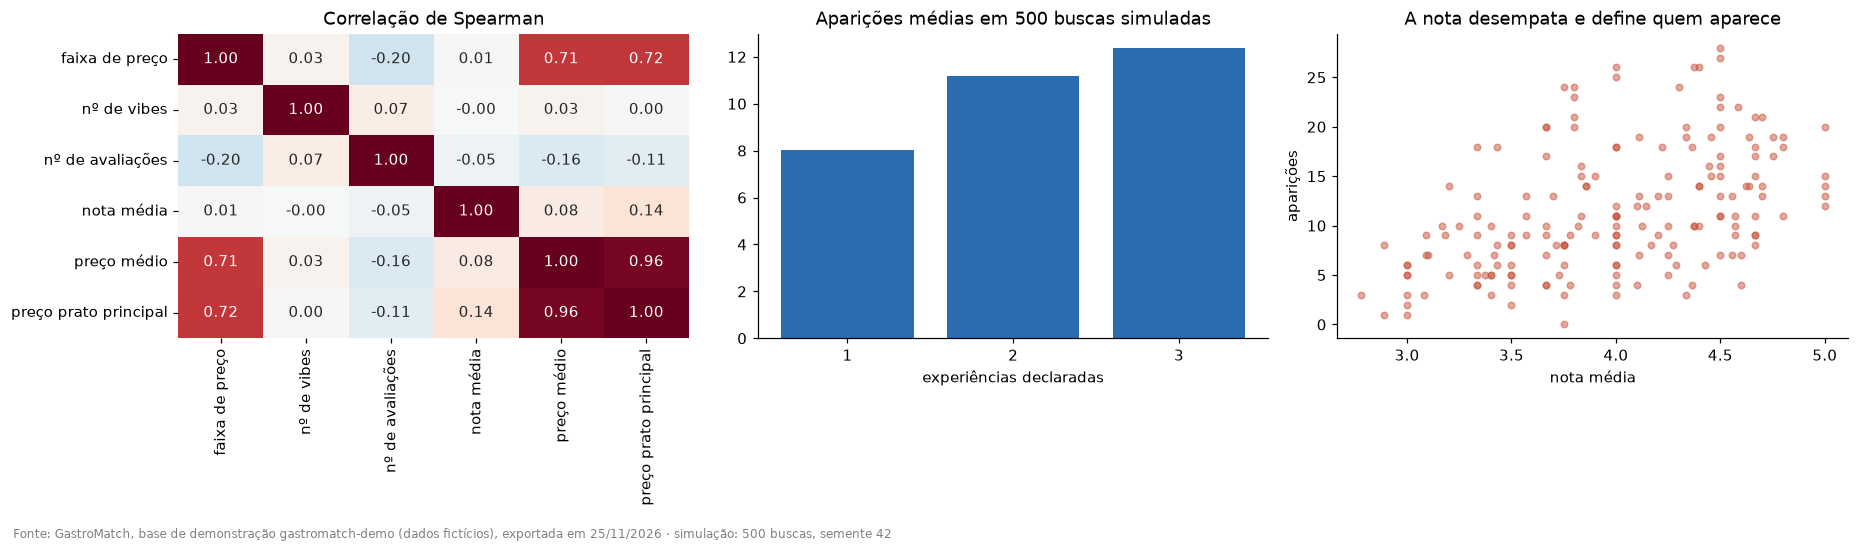

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[0], cbar=False); ax[0].set_title("Correlação de Spearman")
ax[1].bar(por_qtd.index.astype(str), por_qtd["mean"], color="#2b6cb0"); ax[1].set_xlabel("experiências declaradas")
ax[1].set_title("Aparições médias em 500 buscas simuladas")
x = rest.dropna(subset=["nota_media"])
ax[2].scatter(x["nota_media"], x["aparicoes_simulacao"], alpha=.5, s=18, c="#c8553d"); ax[2].set_xlabel("nota média"); ax[2].set_ylabel("aparições")
ax[2].set_title("A nota desempata e define quem aparece")
fig.text(0.01, -0.03, FONTE + " · simulação: 500 buscas, semente 42", fontsize=8, color="gray"); plt.tight_layout()
plt.savefig(FIGURAS / "fig3_correlacao_sensibilidade.png", bbox_inches="tight"); plt.show()

## 4.5 Agrupamento K-means

Atributos padronizados (`StandardScaler`): `faixa_preco`, `nota_media`, `total_avaliacoes` e `qtd_vibes`. Foram usados os 177 restaurantes com nota. O número de grupos *k* vai de 2 a 5 e é escolhido pelo **coeficiente de silhueta**, com `n_init = 20` e `random_state = 42`.

In [10]:
atrib = ["faixa_preco", "nota_media", "total_avaliacoes", "qtd_vibes"]
base_km = rest.dropna(subset=atrib).copy()
X = StandardScaler().fit_transform(base_km[atrib])
silh = {k: silhouette_score(X, KMeans(k, n_init=20, random_state=SEMENTE).fit_predict(X)) for k in range(2, 6)}
k_best = max(silh, key=silh.get)
print("Silhueta por k:", {k: round(v, 3) for k, v in silh.items()}, "→ k escolhido:", k_best)
km = KMeans(k_best, n_init=20, random_state=SEMENTE).fit(X)
base_km["cluster"] = km.labels_
perfil = base_km.groupby("cluster")[atrib + ["preco_medio_cardapio", "aparicoes_simulacao"]].mean().round(2)
perfil["restaurantes"] = base_km["cluster"].value_counts().sort_index()
perfil["vibe mais comum"] = [base_km[base_km.cluster == c].filter(like="vibe_").sum().idxmax().replace("vibe_", "") for c in perfil.index]
perfil["cozinha mais comum"] = [base_km[base_km.cluster == c]["cozinha"].mode()[0] for c in perfil.index]
perfil

Silhueta por k: {2: 0.195, 3: 0.2, 4: 0.217, 5: 0.224} → k escolhido: 5


,faixa_preco,nota_media,total_avaliacoes,qtd_vibes,preco_medio_cardapio,aparicoes_simulacao,restaurantes,vibe mais comum,cozinha mais comum
cluster,,,,,,,,,
0,1.95,4.36,10.02,2.59,48.86,14.98,41,familiar,Italiana
1,2.70,4.41,4.70,1.51,67.74,11.32,37,familiar,Churrasco
2,3.60,3.81,5.98,2.78,82.95,10.95,40,sofisticada,Japonesa
3,1.54,3.87,4.58,2.96,48.17,11.67,24,tranquila,Brasileira
4,1.86,3.36,7.97,1.77,44.15,7.51,35,descontraida,Brasileira


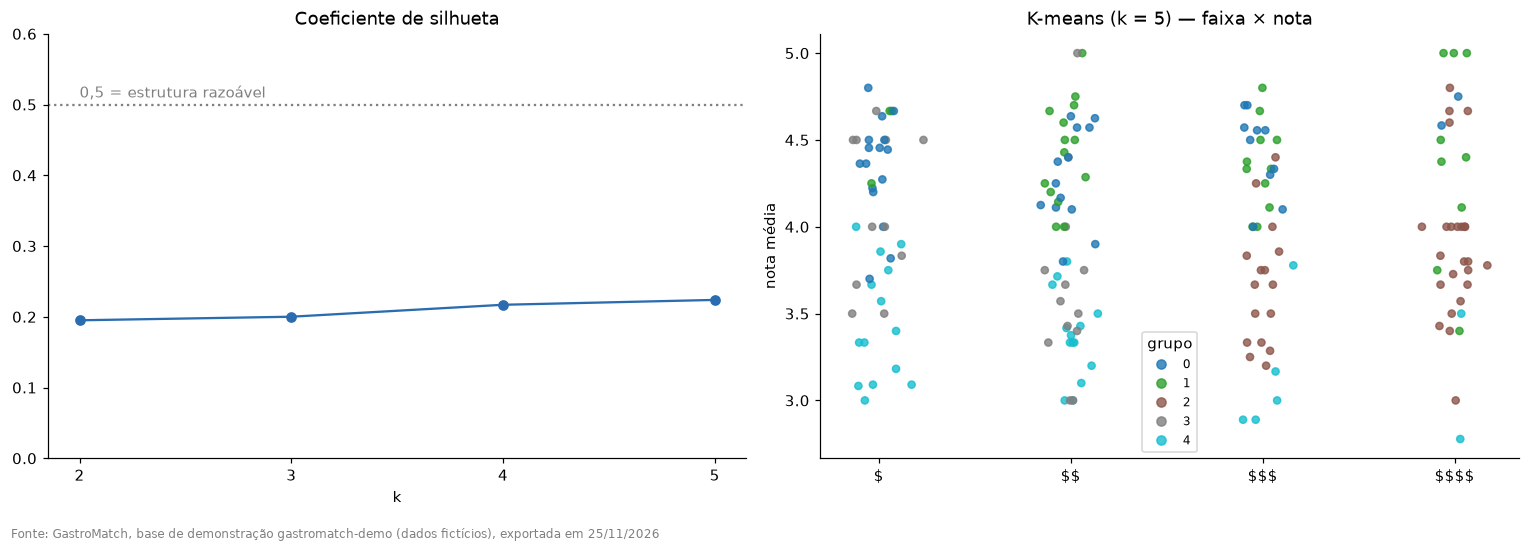

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(list(silh), list(silh.values()), "o-", c="#2b6cb0"); ax[0].axhline(0.5, ls=":", c="gray")
ax[0].text(2, 0.51, "0,5 = estrutura razoável", color="gray"); ax[0].set_ylim(0, 0.6); ax[0].set_xticks(list(silh)); ax[0].set_xlabel("k"); ax[0].set_title("Coeficiente de silhueta")
jit = np.random.default_rng(SEMENTE).normal(0, .08, len(base_km))
sc = ax[1].scatter(base_km["faixa_preco"] + jit, base_km["nota_media"], c=base_km["cluster"], cmap="tab10", s=22, alpha=.8)
ax[1].set_xticks([1, 2, 3, 4], ["$", "$$", "$$$", "$$$$"]); ax[1].set_ylabel("nota média"); ax[1].set_title(f"K-means (k = {k_best}) — faixa × nota")
ax[1].legend(sc.legend_elements()[0], [str(i) for i in range(k_best)], title="grupo", fontsize=8)
fig.text(0.01, -0.03, FONTE, fontsize=8, color="gray"); plt.tight_layout()
plt.savefig(FIGURAS / "fig4_kmeans_restaurantes.png", bbox_inches="tight"); plt.show()

In [12]:
saida = rest.merge(base_km[["restaurante_id", "cluster"]], on="restaurante_id", how="left")
saida[["restaurante_id", "nome_restaurante", "cozinha", "faixa_preco", "cidade", "vibes_lista", "qtd_vibes", "total_avaliacoes", "nota_media",
       "preco_medio_cardapio", "taxa_conversao_cupom", "aparicoes_simulacao", "score_medio_simulado", "cluster"]] \
    .to_csv(PROCESSADOS / "resultado_modelagem_gastromatch.csv", index=False, encoding="utf-8-sig")
testes.to_csv(PROCESSADOS / "testes_kruskal.csv", index=False, encoding="utf-8-sig")
resumo = {"kw_vibe_p_restaurante": float(testes.loc[0, "p (restaurante)"]), "silhueta": {int(k): round(float(v), 3) for k, v in silh.items()},
          "k": int(k_best), "aparicoes_por_qtd_vibes": por_qtd["mean"].to_dict(), "situacoes": pd.Series(situacoes).value_counts().to_dict()}
json.dump(resumo, open(PROCESSADOS / "resumo_modelagem.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("Salvos: resultado_modelagem_gastromatch.csv, testes_kruskal.csv, resumo_modelagem.json e figuras fig1–fig4")

Salvos: resultado_modelagem_gastromatch.csv, testes_kruskal.csv, resumo_modelagem.json e figuras fig1–fig4


## Leitura dos resultados

Interpretação baseada nos números calculados acima:

1. **Satisfação:** nenhum dos quatro fatores muda a nota média de forma significativa no nível do restaurante. No nível de avaliação, cozinha e estado parecem significativos, mas é pseudorreplicação: muitas avaliações do mesmo restaurante contadas como independentes.
2. **Coerência do cadastro:** a faixa declarada acompanha o preço do cardápio (rho ≈ 0,7). As experiências Sofisticada e Romântica aparecem mais nas faixas altas, e Descontraída nas baixas, mas as correlações são **fracas** (|rho| ≤ 0,25).
3. **Recomendação:**
   - A cozinha é decisiva, porque filtra antes de pontuar.
   - Declarar mais experiências aumenta a exposição.
   - Como muitos restaurantes empatam na pontuação, a **nota média funciona como desempate** e tem a correlação mais forte com as aparições.
   - Quase metade das buscas cai em "cozinha em outra cidade", porque o catálogo é esparso por cidade.
4. **Agrupamento:** a silhueta fica bem abaixo de 0,5. Não há grupos naturais bem separados, e os clusters servem só como descrição.